# MM5 lab: build a reliable link (30 min)

**What you get:** a simulator of one link from Alice to Bob. Frames are real bits; the channel adds delay and flips bits (the Binary Symmetric Channel from Lecture 5).
**What you build:** stop-and-wait ARQ, in `student/mm5_link.py`, with Copilot's help.
**What you find out:** things the paper exercises cannot reach, because they need thousands of frames.

| Part | Time | |
|---|---|---|
| A | 5 min | Why a link needs a protocol |
| B | 10 min | Implement stop-and-wait ARQ with Copilot |
| C | 13 min | Pick **two** experiments |
| D | 2 min | Wrap up |

**Rules.** Write your prediction *before* you run a cell. Copilot may write code in `student/`, never in `commsim/`. Answers go in the answer cells, in your own words.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.insert(0, "..")   # the CommSim folder
from commsim import *
from commsim.checks import check_mm5
from student.mm5_link import UtopiaSender, UtopiaReceiver, StopAndWaitSender, StopAndWaitReceiver

print(FrameFormat(max_payload_bytes=64, check="crc8").describe())

preamble          8
dst address       0
src address       0
type (DATA/ACK)   1
seq               1
ack               1
length            6
payload           8 x (1..64)
check (crc8)      8
= overhead        25 bits per DATA frame, ACK frame = 19 bits


Compare this header with Figure 1 of Problem Set 1. The simulator adds one bit: the frame type (DATA or ACK).

## Part A: why a link needs a protocol (5 min)

Same setup as Problem Set 1, Problems 1 and 2: Alice sends 79 frames of 64 bytes at 1 kbit/s, and the one-way delay is 10 ms. The given **Utopia** protocol sends all frames back to back, and Bob accepts everything he receives.

In [2]:
point_to_point(UtopiaSender, UtopiaReceiver, ber=0)

point_to_point: 79 x 64 B, 1000 bit/s, delay 0.01 s, BER 0, crc8
  time simulated       42.43 s
  data frames sent     79  (of which retransmissions: 0)
  ACK frames sent      0
  failed error check   0  (frames)
  delivered correctly  79 of 79 offered
  duplicates           0
  undetected errors    0
  never delivered      0
  goodput              953.2 bit/s  (95.3 % of the link rate)
  mean delay           21.49 s

**A1.** Compare the goodput with your answer to Problem 1(c). Why is it not exactly the same?

> **Answer:** Problem 1(c) gave 960 bit/s; here it is 953 bit/s. Each frame has one extra bit (the frame type), so the efficiency is 512/537 = 0.953 instead of 512/536 = 0.955. And the 10 ms propagation of the last frame adds a little time. (Problem 1(c) also rounded 0.955 to 0.96.)

**A2. Predict first:** with BER = 10⁻³, how many of the 79 frames reach Bob intact? (Use the PER formula from Lecture 5.)

> **Answer:** Prediction: PER = 1 − (1 − 10⁻³)^537 ≈ 0.42, so about 46 frames intact.

point_to_point: 79 x 64 B, 1000 bit/s, delay 0.01 s, BER 0.001, crc8
  time simulated       42.43 s
  data frames sent     79  (of which retransmissions: 0)
  ACK frames sent      0
  failed error check   37  (frames)
  delivered correctly  42 of 79 offered
  duplicates           0
  undetected errors    37
  never delivered      37
  goodput              506.8 bit/s  (50.7 % of the link rate)
  mean delay           20.75 s


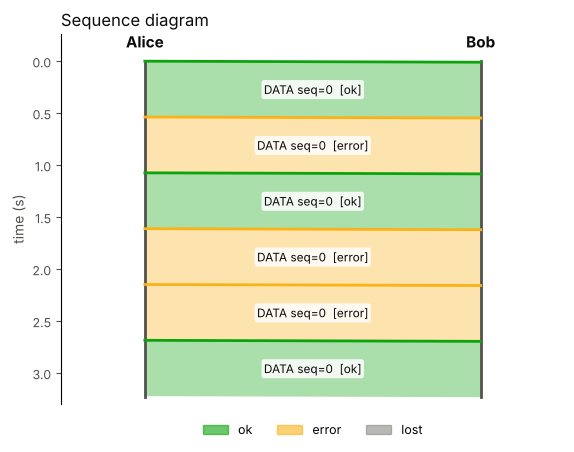

In [3]:
r = point_to_point(UtopiaSender, UtopiaReceiver, ber=1e-3)
print(r)
sequence_diagram(r, max_frames=6);

**A3.** Utopia fails in two different ways. Name them, and name the mechanism from Lecture 5 that fixes each one.

> **Answer:** We got 42 intact (close to the 46 predicted). (1) Corrupted frames are handed to Bob's application as if they were fine: 37 undetected errors. Error detection (the CRC) fixes that, but then Bob just drops them. (2) Nobody resends the lost frames: 37 never arrive. Feedback (ACK) plus retransmission (ARQ) fixes that.

## Part B: implement stop-and-wait ARQ (10 min)

1. Open `student/mm5_link.py`. Read the Utopia example and the specification above `StopAndWaitSender`.
2. Ask Copilot to implement `StopAndWaitSender` and `StopAndWaitReceiver` from the specification. Read what it wrote: you should be able to explain every line.
3. Run the check below. Fix and re-run until all checks pass. (The notebook reloads your file automatically.)

*Tip:* implement it **without** the sequence number first and run the check. Which check fails, and why?

In [4]:
check_mm5(StopAndWaitSender, StopAndWaitReceiver)

PASS  1 perfect channel: 20/20 delivered, 0 duplicates, 0 retransmissions


PASS  2 bit errors: 200/200 delivered, 0 corrupted
PASS  3 lost ACKs: 200/200 delivered, 0 duplicates

All checks passed.


True

point_to_point: 79 x 64 B, 1000 bit/s, delay 0.01 s, BER 0.001, crc8
  time simulated       91.55 s
  data frames sent     143  (of which retransmissions: 64)
  ACK frames sent      82
  failed error check   60  (frames)
  delivered correctly  79 of 79 offered
  duplicates           0
  undetected errors    0
  never delivered      0
  goodput              441.8 bit/s  (44.2 % of the link rate)
  mean delay           48.87 s


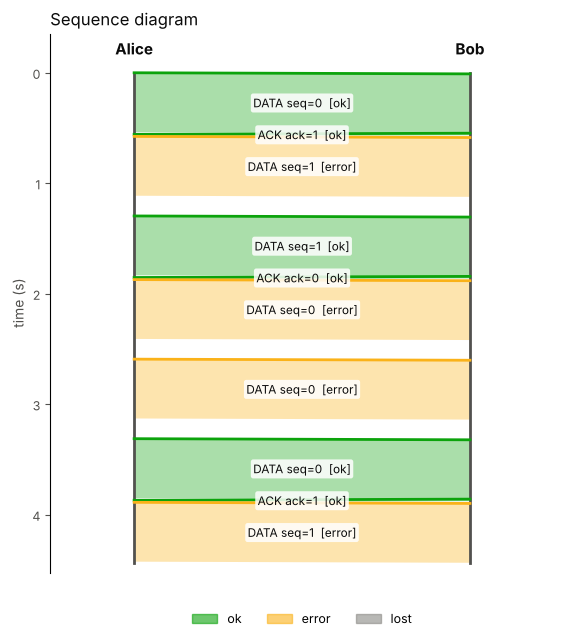

In [5]:
r = point_to_point(StopAndWaitSender, StopAndWaitReceiver, ber=1e-3)
print(r)
sequence_diagram(r, max_frames=10);

**B1.** Compare with Utopia at the same BER: what did ARQ buy, and what did it cost? In the diagram, find a retransmission. What triggered it?

> **Answer:** Everything arrives (79/79, no undetected errors), but goodput drops from 507 to 442 bit/s and the transfer takes 92 s instead of 42 s. The cost is waiting: each frame waits for its ACK, and a lost frame costs a full timeout before it is resent. In the diagram, a DATA frame marked 'error' is followed by silence (Bob stays silent) and then the same seq is sent again when Alice's timer expires. Without the sequence number, check 3 failed: a lost ACK made Bob accept the retransmitted copy as new data.

## Part C: pick two experiments (13 min)

Each experiment runs hundreds or thousands of frames. **Write your prediction first.**

### C1. What is the best frame size?
Problem 1(d) suggested that bigger frames are more efficient, because the overhead is paid once per frame. But a bigger frame is also more likely to be hit by a bit error. Link: 1 Mbit/s, 10 µs delay, CRC-16.

**Predict:** at BER = 10⁻⁴ and at BER = 10⁻³, roughly which payload size gives the highest goodput?

> **Answer:** Prediction: around 64 bytes for 10⁻⁴; smaller, maybe 16 bytes, for 10⁻³.

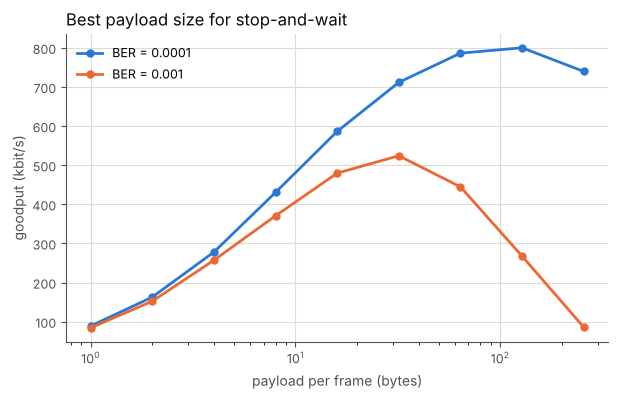

In [6]:
sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256]
curves = {}
for ber in [1e-4, 1e-3]:
    curves[f"BER = {ber:g}"] = [
        point_to_point(StopAndWaitSender, StopAndWaitReceiver, n_packets=300, payload_bytes=L,
                       rate_bps=1e6, prop_delay=1e-5, ber=ber, check="crc16").goodput_bps / 1e3
        for L in sizes]
sweep_plot(sizes, curves, "payload per frame (bytes)", "goodput (kbit/s)", logx=True,
           title="Best payload size for stop-and-wait");

**C1.** Where is the optimum for each BER? Explain the shape of the curve with the overhead and the PER formula.

> **Answer:** The optimum is about 128 bytes at 10⁻⁴ and about 32 bytes at 10⁻³, larger than we predicted for 10⁻⁴. On the left, the fixed overhead (header, CRC, ACK, waiting) dominates. On the right, PER = 1 − (1 − BER)^n grows with the frame length n, so more and more frames have to be resent. The noisier the channel, the shorter the best frame. So Problem 1(d) is only right for a clean channel.

### C2. How far can stop-and-wait reach?
Link: 1 Mbit/s, 64-byte payloads, no bit errors. Signals travel at about 2 × 10⁸ m/s in cable. The pre-lecture reading mentioned Mars: 4 to 24 **minutes** one way.

**Predict:** at what distance is half of the link's capacity wasted?

> **Answer:** Prediction: a few hundred km.

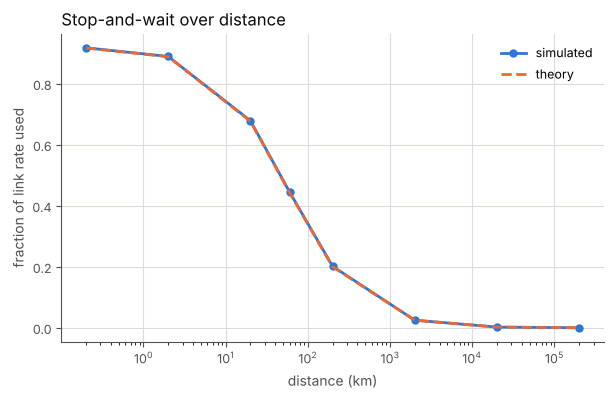

In [7]:
delays = [1e-6, 1e-5, 1e-4, 3e-4, 1e-3, 1e-2, 1e-1, 1]          # one-way delay (s)
distance_km = [d * 2e8 / 1e3 for d in delays]
measured = [point_to_point(StopAndWaitSender, StopAndWaitReceiver, n_packets=50, payload_bytes=64,
                           rate_bps=1e6, prop_delay=d).utilisation for d in delays]
# Our theory: per frame the link is busy with useful bits for 8*64/R seconds,
# but one cycle takes T_data + T_ack + 2 d.
fmt = FrameFormat(64, "crc8")
t_data, t_ack = fmt.data_bits(64) / 1e6, fmt.ack_bits / 1e6
theory = [(8 * 64 / 1e6) / (t_data + t_ack + 2 * d) for d in delays]
sweep_plot(distance_km, {"simulated": measured, "theory": theory}, "distance (km)",
           "fraction of link rate used", logx=True, title="Stop-and-wait over distance");

**C2.** At what distance is half the capacity wasted? What would the utilisation be for Mars, and what would you change in the protocol?

> **Answer:** Half the capacity is lost at about 0.2 ms one-way delay, roughly 40-60 km of cable: much shorter than we predicted. Our theory curve matches the simulation. For Mars (240-1440 s one way) only about 10⁻⁶ of the link would be used. You would have to keep sending new frames while waiting for ACKs (more than one frame in flight, so more than one sequence bit), or add enough redundancy that retransmissions are rarely needed.

### C3. How good is error detection, really?
Lecture 5 said parity is weak and a CRC is strong but not perfect. Count how many **corrupted payloads reach Bob's application** when stop-and-wait runs with each check (2000 payloads of 8 bytes).

**Predict:** rank `none`, `parity`, `crc8`, `crc16` at BER = 10⁻².

> **Answer:** Prediction: none is worst, then parity, crc8 and crc16 near zero.

In [8]:
bers = [1e-3, 3e-3, 1e-2, 3e-2]
print(f"{'check':<8}" + "".join(f"BER {b:<9g}" for b in bers))
for check in ["none", "parity", "crc8", "crc16"]:
    row = []
    for ber in bers:
        r = point_to_point(StopAndWaitSender, StopAndWaitReceiver, n_packets=2000, payload_bytes=8,
                           rate_bps=1e6, prop_delay=1e-5, ber=ber, check=check)
        row.append(r.undetected_errors)
    print(f"{check:<8}" + "".join(f"{n:<13}" for n in row))

check   BER 0.001    BER 0.003    BER 0.01     BER 0.03     


none    120          379          1001         1743         


parity  8            42           383          1569         


crc8    0            0            1            26           


crc16   0            0            0            0            


**C3.** Explain the parity row. Why does it get so bad at high BER, even though ARQ keeps retrying?

> **Answer:** Ranking as predicted, but parity is far worse than we expected: about 1500 of 2000 payloads corrupted at BER 3·10⁻². Parity only catches an odd number of flipped bits. At high BER almost every frame is hit, and ARQ keeps resending until some copy passes the check, which is often one with an even number of errors. So ARQ plus a weak check means retrying until a wrong frame gets through. CRC-8 lets a few through at the highest BER; CRC-16 none in 2000.

## Part D: wrap up (2 min)

Your `student/mm5_link.py` stays in the framework. In **MM6** your link gets neighbours: several Alices share one channel to a base station, and their frames can collide.

After this session, a reference stop-and-wait is added to the framework (`commsim.reference`). MM6 uses it by default, so a bug in anyone's MM5 code cannot block the next lab. You can still plug in your own.

**D1.** One sentence: what surprised you most today?

> **Answer:** That a weak check combined with ARQ can be worse than no retransmission at all, because it keeps rolling the dice until a corrupted frame passes.